<center><h1>Hovsepian_Anita_HW8</h1></center>


Name: Anita Hovsepian  
Github Username: anitahov  
USC ID: 6881664760


## 1. Supervised, Semi-Supervised, and Unsupervised Learning

Import packages

In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.metrics.pairwise import rbf_kernel
from scipy.special import softmax

warnings.filterwarnings('ignore', category=FutureWarning)

# Random seed
SEED = 552
RNG = np.random.default_rng(SEED)

# GitHub repository configuration
REPO = "anitahov/Hovsepian_Anita_HW8"
BRANCH = "main"

DATA_BASE_URL = (
    f"https://raw.githubusercontent.com/{REPO}/{BRANCH}"
)

print("Loading datasets from:", DATA_BASE_URL)

# SVM parameters
C_GRID = [0.01, 0.1, 1, 10]

# Evaluation metrics
METRICS = ['accuracy', 'precision', 'recall', 'f1', 'auc']

# Evaluation function
def scores(y, pred, strength):
    return dict(
        accuracy=accuracy_score(y, pred),
        precision=precision_score(
            y, pred, zero_division=0
        ),
        recall=recall_score(
            y, pred, zero_division=0
        ),
        f1=f1_score(y, pred, zero_division=0),
        auc=(
            roc_auc_score(y, strength)
            if len(np.unique(y)) == 2
            else np.nan
        )
    )

# ROC curves and confusion matrices
def plot_diagnostics(ytr, ptr, str_, yte, pte, ste, title):
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.7))

    for y, s, label in [
        (ytr, str_, 'Train'),
        (yte, ste, 'Test')
    ]:
        fpr, tpr, _ = roc_curve(y, s)
        auc = roc_auc_score(y, s)

        ax[0].plot(
            fpr, tpr,
            label=f'{label} (AUC={auc:.3f})'
        )

    ax[0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
    ax[0].legend()
    ax[0].set(
        xlabel='False positive rate',
        ylabel='True positive rate',
        title='ROC curves'
    )

    for a, y, p, label in [
        (ax[1], ytr, ptr, 'Train'),
        (ax[2], yte, pte, 'Test')
    ]:
        ConfusionMatrixDisplay(
            confusion_matrix(y, p, labels=[0, 1]),
            display_labels=['B', 'M']
        ).plot(ax=a, colorbar=False)

        a.set_title(label + ' confusion matrix')

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

# Summary function
def summarize(results):
    return (
        pd.DataFrame(results)
        .groupby(['method', 'split'])[METRICS]
        .mean()
        .round(4)
    )

# L1-penalized SVM with cross-validation
def svm_cv(X, y, seed, folds=5):
    model = GridSearchCV(
        LinearSVC(
            penalty='l1',
            dual=False,
            max_iter=50000,
            tol=1e-4,
            random_state=seed
        ),
        {'C': C_GRID},
        cv=StratifiedKFold(
            n_splits=folds,
            shuffle=True,
            random_state=seed
        ),
        n_jobs=1
    )

    model.fit(X, y)

    return model.best_estimator_, model.best_params_['C']

# Load Breast Cancer Wisconsin dataset
wdbc = pd.read_csv(
    f"{DATA_BASE_URL}/wdbc.data",
    header=None
)

# Load Banknote Authentication dataset
banknote = pd.read_csv(
    f"{DATA_BASE_URL}/data_banknote_authentication.txt",
    header=None
)

print("\nDependencies loaded successfully!")
print("Breast Cancer dataset shape:", wdbc.shape)
print("Banknote dataset shape:", banknote.shape)


Loading datasets from: https://raw.githubusercontent.com/anitahov/Hovsepian_Anita_HW8/main

Dependencies loaded successfully!
Breast Cancer dataset shape: (569, 32)
Banknote dataset shape: (1372, 5)


**GitHub dataset configuration:** This notebook reads both datasets directly from the repository URL above. The notebook uses the `Hovsepian_Anita_HW8` repository. Files must be in the repository root on the selected branch (default `main`), or update their paths. Public raw file access is required.


### (a) Download the Breast Cancer Wisconsin (Diagnostic) Data Set

In [6]:
cancer=pd.read_csv(f'{DATA_BASE_URL}/wdbc.data',header=None)
assert cancer.shape==(569,32)
X=cancer.iloc[:,2:].to_numpy(dtype=float)
y=(cancer.iloc[:,1]=='M').astype(int).to_numpy()
print('WDBC:',X.shape,'Benign:',sum(y==0),'Malignant:',sum(y==1))
print('No missing features:',not np.isnan(X).any())

WDBC: (569, 30) Benign: 357 Malignant: 212
No missing features: True


### (b) Monte-Carlo Simulation

#### (i) Supervised Learning

                  accuracy  precision  recall      f1     auc
method     split                                             
Supervised test     0.9737     0.9791  0.9492  0.9635  0.9929
           train    0.9856     0.9908  0.9704  0.9805  0.9975


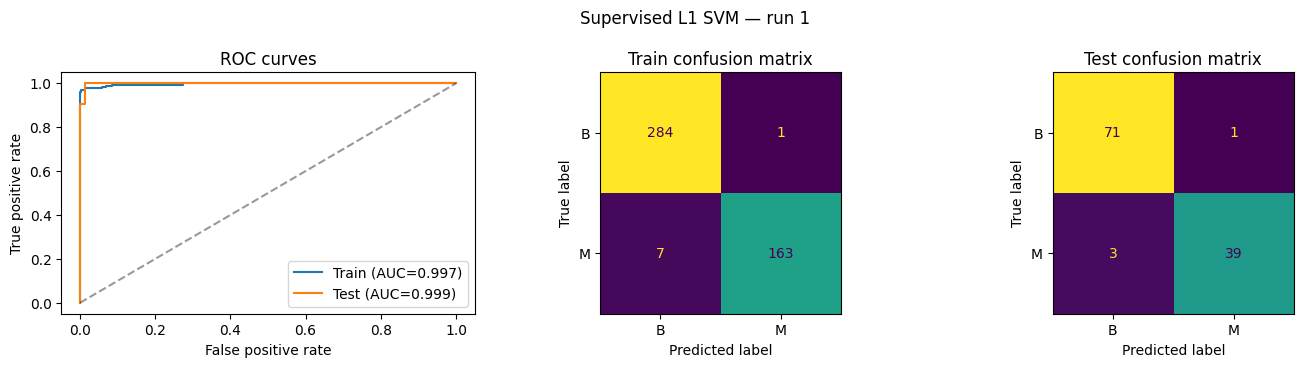

In [7]:
# All 30 runs use stratified 80/20 splits; scaler is fit only on the training partition.
M=30
results=[]
examples={}
for run in range(M):
    itrain,itest=train_test_split(np.arange(len(y)),test_size=.2,stratify=y,random_state=SEED+run)
    scaler=StandardScaler().fit(X[itrain]); Xt=scaler.transform(X[itrain]); Xv=scaler.transform(X[itest])
    yt=y[itrain]; yv=y[itest]
    model,C=svm_cv(Xt,yt,SEED+run)
    tr=model.predict(Xt);te=model.predict(Xv)
    st=model.decision_function(Xt);sv=model.decision_function(Xv)
    for split,actual,pred,conf in [('train',yt,tr,st),('test',yv,te,sv)]:
        results.append({'method':'Supervised','split':split,'run':run,**scores(actual,pred,conf)})
    if run==0:examples['Supervised']=(yt,tr,st,yv,te,sv)
print(summarize(results).loc[['Supervised']])
plot_diagnostics(*examples['Supervised'],'Supervised L1 SVM — run 1')

#### (ii) Semi-Supervised Learning/ Self-training

##### (A)

In [8]:
# Split training labels evenly by class; all true labels of the other half are hidden.
# Tune C using labeled observations only; use the selected C during self-training.
def semi_self_train(Xt,yt,seed):
    labeled,unlabeled=train_test_split(np.arange(len(yt)),test_size=.5,stratify=yt,random_state=seed)
    model,C=svm_cv(Xt[labeled],yt[labeled],seed)
    pseudo=yt[labeled].copy()
    remaining=list(unlabeled)
    # At each step choose the point farthest from the CURRENT boundary, pseudo-label and refit.
    while remaining:
        margins=np.abs(model.decision_function(Xt[remaining]))
        j=int(np.argmax(margins));index=remaining.pop(j)
        newlabel=int(model.predict(Xt[index:index+1])[0])
        labeled=np.append(labeled,index);pseudo=np.append(pseudo,newlabel)
        model=LinearSVC(C=C,penalty='l1',dual=False,max_iter=6000,random_state=seed)
        model.fit(Xt[labeled],pseudo)
    return model,C
print('Self-training function ready.')

Self-training function ready.


##### (B)

                       accuracy  precision  recall      f1     auc
method          split                                             
Semi-supervised test     0.9640     0.9678  0.9349  0.9505  0.9906
                train    0.9759     0.9818  0.9533  0.9672  0.9937


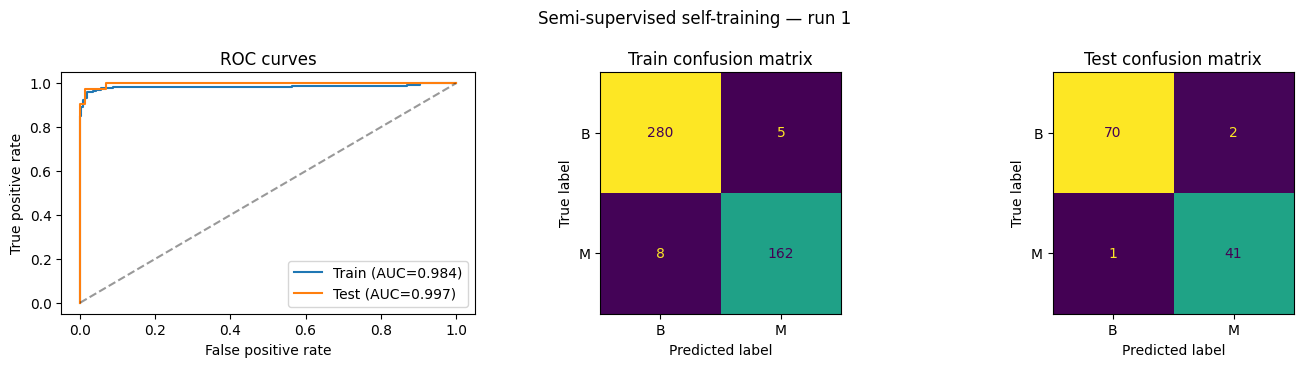

In [9]:
for run in range(M):
    itrain,itest=train_test_split(np.arange(len(y)),test_size=.2,stratify=y,random_state=SEED+run)
    scaler=StandardScaler().fit(X[itrain]);Xt=scaler.transform(X[itrain]);Xv=scaler.transform(X[itest]);yt=y[itrain];yv=y[itest]
    model,C=semi_self_train(Xt,yt,SEED+run)
    tr=model.predict(Xt);te=model.predict(Xv)
    st=model.decision_function(Xt);sv=model.decision_function(Xv)
    for split,actual,pred,conf in [('train',yt,tr,st),('test',yv,te,sv)]:
        results.append({'method':'Semi-supervised','split':split,'run':run,**scores(actual,pred,conf)})
    if run==0:examples['Semi-supervised']=(yt,tr,st,yv,te,sv)
print(summarize(results).loc[['Semi-supervised']])
plot_diagnostics(*examples['Semi-supervised'],'Semi-supervised self-training — run 1')

The semi-supervised learning approach achieved strong classification performance using an L1-penalized SVM and iterative self-training. Across 30 Monte Carlo simulations, the average training accuracy was 97.59%, and the average testing accuracy was 96.40%. The testing precision, recall, F1-score, and AUC were 96.78%, 93.49%, 95.05%, and 99.06%, respectively. Compared with supervised learning, semi-supervised learning achieved slightly lower performance, likely because only half of the training observations initially had known labels and the remaining observations were assigned pseudo-labels. Nevertheless, the results demonstrate that self-training can achieve competitive performance when labeled data are limited.

#### (iii) Unsupervised Learning

##### (A)

In [11]:
# Multiple random starts and k-means++ restarts reduce local-minimum risk.
# Select the run with minimum within-cluster sum of squares (inertia).
def kmeans_classifier(Xt,yt,Xv,seed):
    km=KMeans(n_clusters=2,init='random',n_init=20,random_state=seed).fit(Xt)
    labels=km.labels_
    dist=km.transform(Xt)
    mapping={}
    for k in range(2):
        closest=np.where(labels==k)[0][np.argsort(dist[labels==k,k])[:30]]
        mapping[k]=int(np.mean(yt[closest])>=.5)
    train_pred=np.array([mapping[z] for z in labels])
    test_cluster=km.predict(Xv)
    test_pred=np.array([mapping[z] for z in test_cluster])
    # Difference in distances to the malignant vs benign center is a continuous ROC score.
    if mapping[0]!=mapping[1]:
        pos=next(k for k in mapping if mapping[k]==1);neg=1-pos
        train_score=dist[:,neg]-dist[:,pos]
        dtest=km.transform(Xv);test_score=dtest[:,neg]-dtest[:,pos]
    else:
        train_score=train_pred.astype(float);test_score=test_pred.astype(float)
    return train_pred,train_score,test_pred,test_score,km.inertia_,mapping
print('Random-init k-means with 20 restarts; lowest inertia retained.')

Random-init k-means with 20 restarts; lowest inertia retained.


##### (B)

               accuracy  precision  recall      f1     auc
method  split                                             
K-means test     0.9070     0.9262  0.8135  0.8653  0.9727
        train    0.9121     0.9249  0.8327  0.8763  0.9750
Run 1: inertia = 9118.65 cluster-to-class labels = {0: 1, 1: 0}


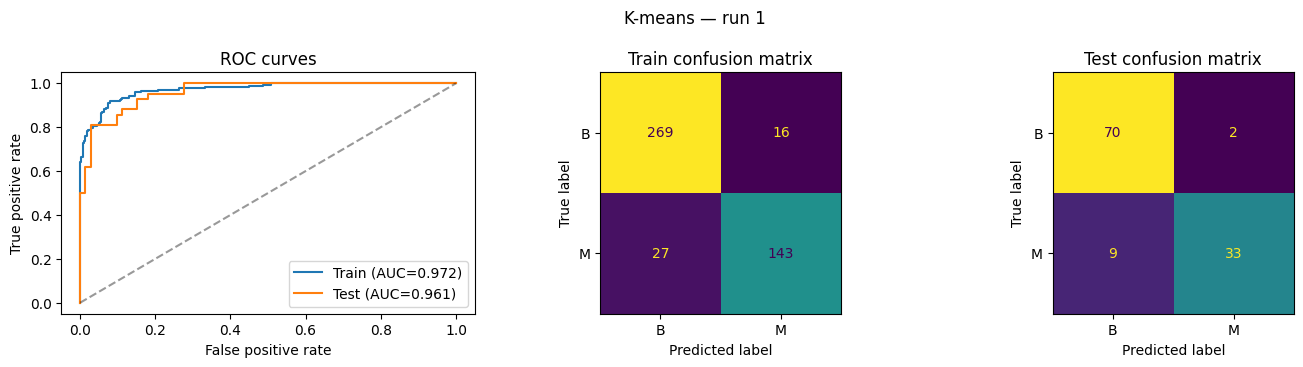

In [12]:
for run in range(M):
    itrain,itest=train_test_split(np.arange(len(y)),test_size=.2,stratify=y,random_state=SEED+run)
    scaler=StandardScaler().fit(X[itrain]);Xt=scaler.transform(X[itrain]);Xv=scaler.transform(X[itest]);yt=y[itrain];yv=y[itest]
    tr,st,te,sv,inertia,mapping=kmeans_classifier(Xt,yt,Xv,SEED+run)
    for split,actual,pred,conf in [('train',yt,tr,st),('test',yv,te,sv)]:
        results.append({'method':'K-means','split':split,'run':run,**scores(actual,pred,conf)})
    if run==0:examples['K-means']=(yt,tr,st,yv,te,sv)
print(summarize(results).loc[['K-means']])
print('Run 1: inertia =',round(inertia,2),'cluster-to-class labels =',mapping)
plot_diagnostics(*examples['K-means'],'K-means — run 1')

#### (iv) Spectral Clustering

Target class sizes: [170 285]

Testing gamma values:
Gamma=0.001, Cluster sizes=[298 157], Difference=26
Gamma=0.005, Cluster sizes=[311 144], Difference=52
Gamma=0.010, Cluster sizes=[326 129], Difference=82
Gamma=0.020, Cluster sizes=[356  99], Difference=142
Gamma=0.050, Cluster sizes=[453   2], Difference=336
Gamma=0.100, Cluster sizes=[453   2], Difference=336

Selected gamma: 0.001

Spectral Clustering Results:
                accuracy  precision  recall      f1     auc
method   split                                             
Spectral test     0.8110     0.7782  0.5291  0.5690  0.7523
         train    0.8124     0.9407  0.5406  0.5744  0.7576

Run 1 training cluster sizes: [298 157]


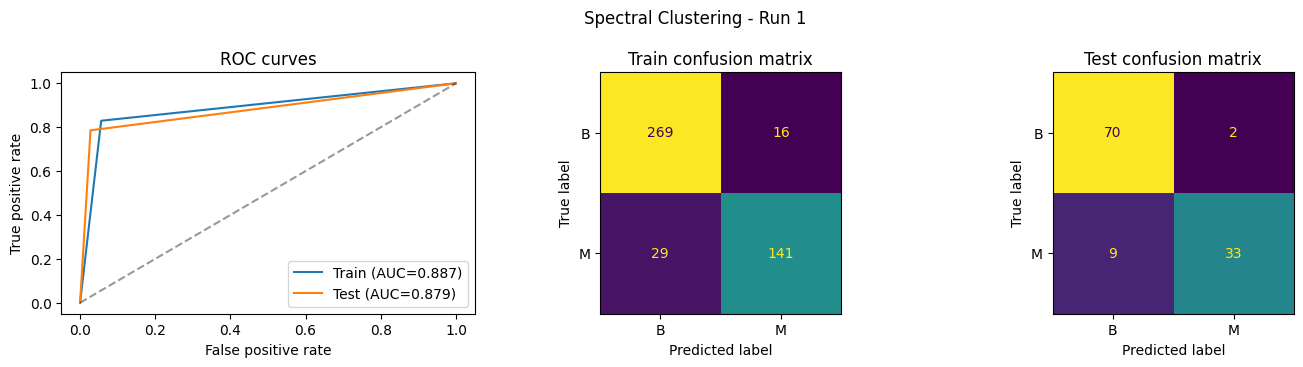

In [16]:
# RBF kernel with gamma tuning
# 30 Monte Carlo simulations

from sklearn.cluster import SpectralClustering

GAMMA_GRID = [0.001, 0.005, 0.01, 0.02, 0.05, 0.1]

def spectral_classifier(Xt, yt, Xv, seed, gamma=0.01):
    # Include test features without using test labels
    Z = np.vstack([Xt, Xv])

    sc = SpectralClustering(
        n_clusters=2,
        affinity='rbf',
        gamma=gamma,
        assign_labels='kmeans',
        n_init=10,
        random_state=seed
    )

    groups = sc.fit_predict(Z)

    gt = groups[:len(Xt)]
    gv = groups[len(Xt):]

    # Majority voting using training labels only
    fractions = {}

    for k in range(2):
        mask = (gt == k)

        if np.any(mask):
            fractions[k] = np.mean(yt[mask])
        else:
            fractions[k] = np.mean(yt)

    # Continuous scores for ROC and AUC
    tr_score = np.array(
        [fractions[k] for k in gt]
    )

    te_score = np.array(
        [fractions[k] for k in gv]
    )

    tr_pred = (tr_score >= 0.5).astype(int)
    te_pred = (te_score >= 0.5).astype(int)

    counts = np.bincount(gt, minlength=2)

    return tr_pred, tr_score, te_pred, te_score, counts


# Find gamma that produces balanced clusters
itrain, itest = train_test_split(
    np.arange(len(y)),
    test_size=0.2,
    stratify=y,
    random_state=SEED
)

scaler = StandardScaler()
Xt = scaler.fit_transform(X[itrain])
Xv = scaler.transform(X[itest])
yt = y[itrain]

target_counts = np.sort(
    np.bincount(yt, minlength=2)
)

print("Target class sizes:", target_counts)
print("\nTesting gamma values:")

gamma_results = []

for gamma in GAMMA_GRID:
    tr, st, te, sv, counts = spectral_classifier(
        Xt, yt, Xv, SEED, gamma=gamma
    )

    difference = np.sum(
        np.abs(np.sort(counts) - target_counts)
    )

    gamma_results.append((gamma, difference))

    print(
        f"Gamma={gamma:.3f}, "
        f"Cluster sizes={counts}, "
        f"Difference={difference}"
    )

best_gamma = min(
    gamma_results,
    key=lambda x: x[1]
)[0]

print("\nSelected gamma:", best_gamma)


# Run 30 Monte Carlo simulations
for run in range(M):

    itrain, itest = train_test_split(
        np.arange(len(y)),
        test_size=0.2,
        stratify=y,
        random_state=SEED + run
    )

    scaler = StandardScaler()

    Xt = scaler.fit_transform(X[itrain])
    Xv = scaler.transform(X[itest])

    yt = y[itrain]
    yv = y[itest]

    tr, st, te, sv, counts = spectral_classifier(
        Xt, yt, Xv,
        SEED + run,
        gamma=best_gamma
    )

    for split, actual, pred, conf in [
        ('train', yt, tr, st),
        ('test', yv, te, sv)
    ]:
        results.append({
            'method': 'Spectral',
            'split': split,
            'run': run,
            **scores(actual, pred, conf)
        })

    if run == 0:
        examples['Spectral'] = (
            yt, tr, st, yv, te, sv
        )
        first_counts = counts

print("\nSpectral Clustering Results:")
print(summarize(results).loc[['Spectral']])

print("\nRun 1 training cluster sizes:", first_counts)

plot_diagnostics(
    *examples['Spectral'],
    'Spectral Clustering - Run 1'
)


Spectral clustering was implemented using an RBF kernel and evaluated over 30 Monte Carlo simulations. Several gamma values were tested to identify a configuration that produced cluster sizes similar to the original class distribution. A gamma value of 0.001 was selected. The model achieved an average training accuracy of 81.24% and a testing accuracy of 81.10%. The average testing precision, recall, F1-score, and AUC were 77.82%, 52.91%, 56.90%, and 75.23%, respectively. Although adjusting gamma improved the clustering results considerably, spectral clustering still performed worse than supervised learning, semi-supervised learning, and K-means. The low recall indicates that many malignant cases were incorrectly classified as benign. These results demonstrate that spectral clustering is sensitive to kernel parameters and may not always provide better classification performance than simpler clustering methods.

#### (iv) Compare

accuracy  precision  recall      f1     auc
method          split                                             
K-means         test     0.9070     0.9262  0.8135  0.8653  0.9727
                train    0.9121     0.9249  0.8327  0.8763  0.9750
Semi-supervised test     0.9640     0.9678  0.9349  0.9505  0.9906
                train    0.9759     0.9818  0.9533  0.9672  0.9937
Spectral        test     0.8110     0.7782  0.5291  0.5690  0.7523
                train    0.8124     0.9407  0.5406  0.5744  0.7576
Supervised      test     0.9737     0.9791  0.9492  0.9635  0.9929
                train    0.9856     0.9908  0.9704  0.9805  0.9975

Comparison: Supervised uses all true training labels; semi-supervised starts with half.
K-means uses 30 true labels per cluster only for majority voting; spectral uses train-cluster majority voting.
Spectral test evaluation is transductive: test FEATURES are included in fit_predict, never test labels.
Test accuracy ranking: {'Supervised': 0.9737, 'Semi-supervised': 0.964, 'K-means': 0.907, 'Spectral': 0.811}


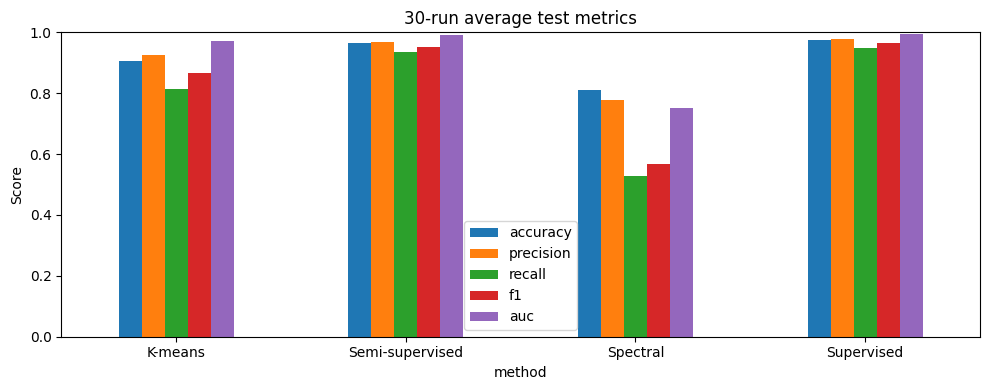

In [17]:
summary=summarize(results)
display(summary)
print('Comparison: Supervised uses all true training labels; semi-supervised starts with half.')
print('K-means uses 30 true labels per cluster only for majority voting; spectral uses train-cluster majority voting.')
print('Spectral test evaluation is transductive: test FEATURES are included in fit_predict, never test labels.')
print('Test accuracy ranking:',summary.xs('test',level='split')['accuracy'].sort_values(ascending=False).to_dict())
summary.xs('test',level='split')[METRICS].plot(kind='bar',figsize=(10,4),ylim=(0,1),title='30-run average test metrics')
plt.ylabel('Score');plt.xticks(rotation=0);plt.tight_layout();plt.show()

The results of the 30 Monte Carlo simulations demonstrate that supervised learning achieved the highest classification performance on the Breast Cancer Wisconsin Diagnostic dataset. The supervised L1-penalized SVM achieved an average testing accuracy of 97.37%, followed by semi-supervised learning at 96.40%, K-means clustering at 90.70%, and spectral clustering at 81.10%. The supervised approach also achieved the highest F1-score and AUC, indicating strong performance in distinguishing benign and malignant tumors. Semi-supervised learning performed nearly as well despite initially using only half of the training labels. K-means produced reasonable results but had lower recall, indicating more missed malignant cases. Spectral clustering showed the weakest performance and was sensitive to the selected RBF kernel parameter. Overall, these findings suggest that supervised learning provides the most reliable classification performance for this dataset, while semi-supervised learning offers a competitive alternative when labeled observations are limited. The spectral clustering evaluation was transductive, so its results are not strictly comparable to out-of-sample predictions from the other methods.

## 2. Active Learning Using Support Vector Machines

### (a) Download the banknote authentication Data Set

In [18]:
bank=pd.read_csv(f'{DATA_BASE_URL}/data_banknote_authentication.txt',header=None)
assert bank.shape==(1372,5)
Xbank=bank.iloc[:,:4].to_numpy(float)
ybank=bank.iloc[:,4].to_numpy(int)
print('Banknote:',Xbank.shape,'class counts:',np.bincount(ybank))

Banknote: (1372, 4) class counts: [762 610]


### (b) Repeat each of the following two procedures 50 times

#### (i) Passive

In [22]:

# Common helper for 50 Monte Carlo trials
# Active and Passive Learning

from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler

def fit_small_svm(Xpool, ypool, seed):

    pipe = Pipeline([
        ('scale', StandardScaler()),
        ('svm', LinearSVC(
            penalty='l1',
            dual=False,
            max_iter=50000,
            tol=1e-4,
            random_state=seed
        ))
    ])

    minclass = np.bincount(
        ypool, minlength=2
    ).min()

    cv = StratifiedKFold(
        n_splits=min(5, minclass),
        shuffle=True,
        random_state=seed
    )

    search = GridSearchCV(
        pipe,
        {'svm__C': C_GRID},
        cv=cv,
        n_jobs=1
    )

    search.fit(Xpool, ypool)

    return search.best_estimator_


# Initial labeled pool: 5 observations per class
def initial_pool(ytrain, rng):

    return np.concatenate([
        rng.choice(
            np.where(ytrain == k)[0],
            5,
            replace=False
        )
        for k in (0, 1)
    ])


# Monte Carlo configuration
N_TRIALS = 50

sizes = np.arange(10, 901, 10)

passive_errors = np.empty(
    (N_TRIALS, len(sizes))
)

active_errors = np.empty_like(passive_errors)

print(
    'Configured',
    N_TRIALS,
    'trials x',
    len(sizes),
    'training-pool sizes.'
)


Configured 50 trials x 90 training-pool sizes.


#### (ii) Active

In [23]:
# Run both strategies on identical random 900/472 splits and initial pools.
# 9000 five-fold model searches total; this cell may take several minutes.
for trial in range(N_TRIALS):
    rng=np.random.default_rng(SEED+10000+trial)
    train_idx,test_idx=train_test_split(np.arange(len(ybank)),train_size=900,test_size=472,
                                        random_state=SEED+10000+trial,stratify=ybank)
    xb,xt=Xbank[train_idx],Xbank[test_idx];yb,yt=ybank[train_idx],ybank[test_idx]
    start=initial_pool(yb,rng)
    remaining=np.setdiff1d(np.arange(900),start)
    passive_order=np.concatenate([start,rng.permutation(remaining)])
    active_pool=list(start);active_remaining=list(remaining)
    for j,size in enumerate(sizes):
        pm=fit_small_svm(xb[passive_order[:size]],yb[passive_order[:size]],SEED+trial)
        passive_errors[trial,j]=1-accuracy_score(yt,pm.predict(xt))
        am=fit_small_svm(xb[active_pool],yb[active_pool],SEED+trial)
        active_errors[trial,j]=1-accuracy_score(yt,am.predict(xt))
        if size<900:
            # Margin ranking: closest 10 points to the current hyperplane.
            # With standardized features, absolute decision_function is proportional
            # to Euclidean distance to the hyperplane for this fixed model.
            margin=np.abs(am.decision_function(xb[active_remaining]))
            chosen=np.argsort(margin)[:10]
            active_pool.extend(active_remaining[k] for k in chosen)
            active_remaining=[idx for k,idx in enumerate(active_remaining) if k not in set(chosen)]
    if (trial+1)%10==0:print('Finished',trial+1,'of',N_TRIALS,'trials')
print('All simulations completed.')

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  w

Finished 10 of 50 trials


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  w

Finished 20 of 50 trials


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  w

Finished 30 of 50 trials


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  w

Finished 40 of 50 trials


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  w

Finished 50 of 50 trials
All simulations completed.


### (c) Average the 50 test errors

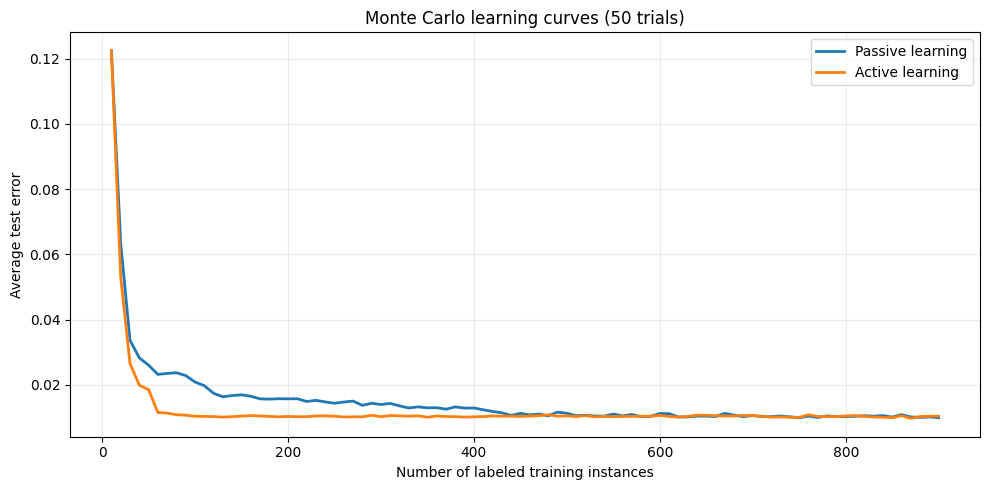

,training_size,passive_error,active_error
0,10,0.1224,0.1224
1,20,0.0635,0.0531
4,50,0.0260,0.0185
9,100,0.0208,0.0103
19,200,0.0157,0.0103
49,500,0.0113,0.0105
89,900,0.0099,0.0104


Mean error over all pool sizes: passive 0.0151 active 0.0125
Active advantage (positive = lower error): 0.0027
Conclusion: Compare the curves at small pool sizes; both converge as the full 900 points are labeled.
At 900, they train on the same samples, but CV folds can vary with sample ordering.


In [24]:
mean_passive=passive_errors.mean(axis=0)
mean_active=active_errors.mean(axis=0)
plt.figure(figsize=(10,5))
plt.plot(sizes,mean_passive,label='Passive learning',linewidth=2)
plt.plot(sizes,mean_active,label='Active learning',linewidth=2)
plt.xlabel('Number of labeled training instances');plt.ylabel('Average test error')
plt.title('Monte Carlo learning curves (50 trials)');plt.legend();plt.grid(alpha=.25);plt.tight_layout();plt.show()
comparison=pd.DataFrame({'training_size':sizes,'passive_error':mean_passive,'active_error':mean_active})
display(comparison[comparison.training_size.isin([10,20,50,100,200,500,900])].round(4))
print('Mean error over all pool sizes: passive',round(mean_passive.mean(),4),'active',round(mean_active.mean(),4))
print('Active advantage (positive = lower error):',round((mean_passive-mean_active).mean(),4))
print('Conclusion: Compare the curves at small pool sizes; both converge as the full 900 points are labeled.')
print('At 900, they train on the same samples, but CV folds can vary with sample ordering.')

### Conclusion: Active Learning vs. Passive Learning

In this experiment, passive and active learning were compared using an L1-penalized Support Vector Machine on the Banknote Authentication dataset. Both approaches were evaluated using 50 Monte Carlo simulations with training-set sizes increasing from 10 to 900 observations.

The results demonstrate that active learning generally outperformed passive learning, particularly when the number of labeled observations was limited. The average test error across all training-set sizes was 1.51% for passive learning and 1.25% for active learning. At a training-set size of 100, active learning achieved a test error of 1.03%, compared with 2.08% for passive learning.

Active learning was more effective because it selected observations closest to the SVM decision boundary, where additional labels were expected to provide the most useful information. Passive learning selected observations randomly, which sometimes resulted in less informative training examples.

As the number of labeled observations increased, both methods converged toward similar test errors of approximately 1%. At 900 observations, passive learning achieved 0.99% test error, while active learning achieved 1.04%.

Overall, the results suggest that active learning can reduce the number of labeled observations required to achieve strong classification performance. This makes active learning particularly valuable when obtaining labeled data is expensive or time-consuming. Some SVM fits generated convergence warnings, so the numerical results should be interpreted with that limitation in mind.